# 04 — Single Sérsic mock-pipeline validation, perfect observation

Question: once FITS I/O, cutout, source detection, background subtraction, empirical noise estimation, segmentation, masking, PSF model, sky model, and real-fit machinery are included, does a controlled mock still recover the truth?


## Validation logic

This notebook is intentionally narrow. It tests one additional layer of complexity relative to the previous notebook. The goal is not to make a pretty demo; the goal is to know exactly where a discrepancy first appears.

BayMorph mask convention: `mask=True` means excluded pixel.


In [1]:

from pathlib import Path
import json
import yaml
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from astropy.io import fits

from baymorph.models import SersicModel
from baymorph.simulation.psf import GaussianPSF, convolve_with_psf
from baymorph.pipeline.config import load_resolved_config
from baymorph.pipeline.image_preparation import prepare_real_image_from_config, load_image_preparation_products
from baymorph.pipeline.real_fit import run_real_fit_from_config


def show_image_triplet(a, b, c, titles):
    fig, axes = plt.subplots(1, 3, figsize=(15, 4))
    for ax, img, title in zip(axes, [a, b, c], titles):
        im = ax.imshow(img, origin="lower")
        ax.set_title(title)
        plt.colorbar(im, ax=ax, fraction=0.046)
    plt.tight_layout()
    plt.show()


def compare_truth(best_parameters, truth):
    rows = []
    for k in ["flux", "re", "n", "q", "theta", "x0", "y0", "sky"]:
        if k not in best_parameters:
            continue
        tv = truth.get(k, 0.0 if k == "sky" else np.nan)
        bv = best_parameters[k]
        if k == "theta":
            tv = np.rad2deg(tv)
            bv = np.rad2deg(bv)
            unit = "deg"
        else:
            unit = ""
        rows.append({"parameter": k, "truth": tv, "best_ML": bv, "best_minus_truth": bv - tv, "unit": unit})
    return pd.DataFrame(rows)


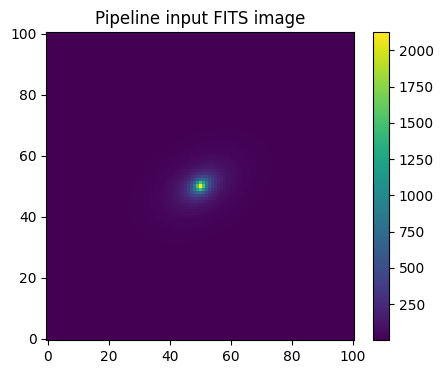

In [2]:

# Current BayMorph real-fit machinery expects a PSF and a sky parameter.
# Therefore this pipeline validation uses a known Gaussian PSF and zero injected sky/noise.
# This is not fitter-only: it goes through FITS I/O, cutout, source detection, background estimation, segmentation, mask creation, and run_real_fit_from_config.

workdir = Path("validation_outputs/04_mock_pipeline_perfect")
workdir.mkdir(parents=True, exist_ok=True)

shape = (101, 101)
psf_fwhm = 2.0
truth = {
    "flux": 1.0e5,
    "re": 8.0,
    "n": 2.0,
    "q": 0.65,
    "theta": np.deg2rad(30.0),
    "x0": 50.0,
    "y0": 50.0,
    "sky": 0.0,
}

intrinsic = SersicModel(**{k: truth[k] for k in ["flux", "re", "n", "q", "theta", "x0", "y0"]}).render(shape)
image = convolve_with_psf(intrinsic, GaussianPSF(psf_fwhm)) + truth["sky"]
image_path = workdir / "mock_single_sersic_psf_no_noise.fits"
fits.writeto(image_path, image, overwrite=True)

plt.figure(figsize=(5,4))
plt.imshow(image, origin="lower")
plt.colorbar()
plt.title("Pipeline input FITS image")
plt.show()


In [ ]:

config = {
    "object": {"name": "mock_single_sersic_pipeline_perfect"},
    "data": {
        "image_path": str(image_path),
        "target_position": {"x": 50, "y": 50},
        "cutout": {"mode": "fixed", "size": 101},
    },
    "outputs": {"root": str(workdir / "outputs"), "overwrite": True},
    "preparation": {
        "background": {"method": "empirical", "box_size": 30, "filter_size": 3},
        "noise": {"method": "empirical"},
        "detection": {"n_sigma": 2.0, "n_levels": 32, "npixels": 10},
    },
    "masking": {
        "connected_source": {"enabled": True},
        "star_halo": {"enabled": False},
        "interactive_refinement": {"enabled": False},
    },
    "psf": {"type": "gaussian", "gaussian": {"fwhm": psf_fwhm}},
    "fit": {
        "models": ["single_sersic"],
        "sampler": {"name": "dynesty", "nlive": 300, "sample": "rwalk", "dlogz": 0.1, "seed": 46, "n_processes": 1},
        "priors": {
            "single_sersic": {
                "flux": {"min_factor": 0.7, "max_factor": 1.3},
                "re": {"min": 5.0, "max": 11.0},
                "n": {"min": 1.0, "max": 3.5},
                "q": {"min": 0.45, "max": 0.85},
                "theta": {"min": "-pi/2", "max": "pi/2"},
                "x0": {"offset": 2.0},
                "y0": {"offset": 2.0},
                "sky": {"min": -10.0, "max": 10.0},
            }
        },
    },
    "diagnostics": {"format": "pdf", "corner": True, "residual": True, "radial_profile": True, "posterior_profile_bands": False},
}

config_path = workdir / "config_mock_pipeline_perfect.yaml"
with open(config_path, "w") as f:
    yaml.safe_dump(config, f, sort_keys=False)

print(config_path)


validation_outputs/04_mock_pipeline_perfect/config_mock_pipeline_perfect.yaml


background estimated: 0.4266136223845124
target label: 1
noise median: 0.28838197025044715
masked fraction: 0.0


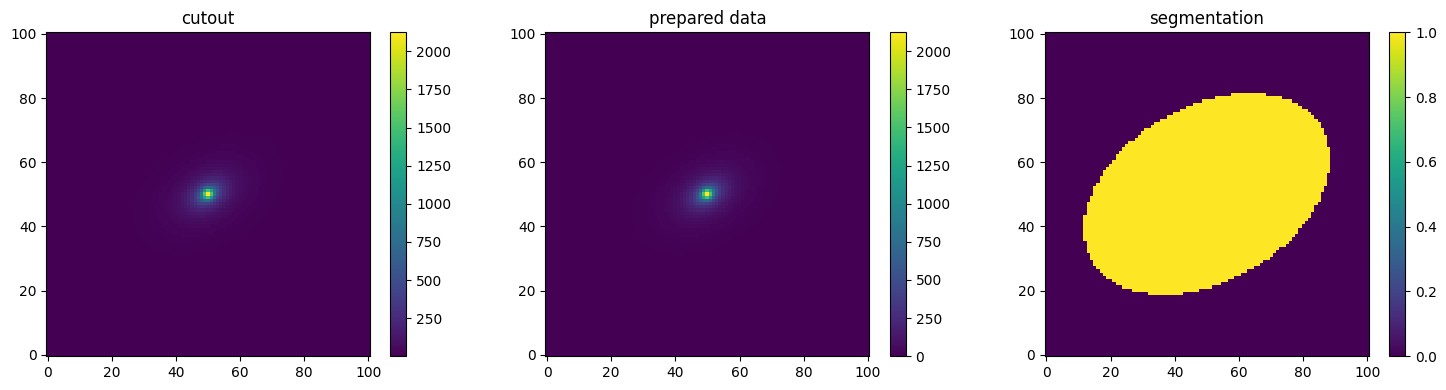

In [4]:

resolved = load_resolved_config(config_path)
prep = prepare_real_image_from_config(resolved, save=True)
print("background estimated:", prep.background)
print("target label:", prep.target_label)
print("noise median:", np.nanmedian(prep.noise))
print("masked fraction:", np.mean(prep.contaminant_mask))
show_image_triplet(prep.cutout, prep.prepared_data, prep.segmentation, ["cutout", "prepared data", "segmentation"])


iter: 23237 | +300 | bound: 81 | nc: 1 | ncall: 631572 | eff(%):  3.729 | loglstar:   -inf < 3309.958 <    inf | logz: 3234.921 +/-  0.488 | dlogz:  0.000 >  0.100                                   

,parameter,truth,best_ML,best_minus_truth,unit
0,flux,100000.00,100014.820336,1.482034e+01,
1,re,8.00,8.002197,2.196761e-03,
2,n,2.00,2.000752,7.520809e-04,
3,q,0.65,0.649930,-7.021178e-05,
4,theta,30.00,29.999103,-8.974260e-04,deg
5,x0,50.00,50.000000,2.992616e-07,
6,y0,50.00,50.000000,-4.283174e-07,
7,sky,0.00,-0.427280,-4.272799e-01,


chi2: 1.163563737325021
reduced chi2: 0.00011415321665113519


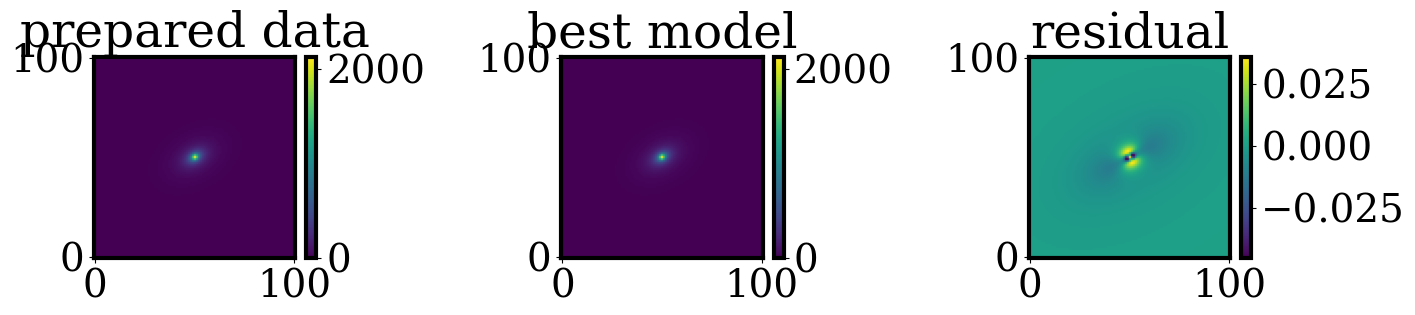

In [5]:

products = run_real_fit_from_config(resolved)
fit = products["single_sersic"]
display(compare_truth(fit.best_parameters, truth))
print("chi2:", fit.chi2)
print("reduced chi2:", fit.reduced_chi2)
show_image_triplet(prep.prepared_data, fit.best_model_image, fit.residual, ["prepared data", "best model", "residual"])

assert abs(fit.best_parameters["x0"] - truth["x0"]) < 0.5
assert abs(fit.best_parameters["y0"] - truth["y0"]) < 0.5
assert abs(fit.best_parameters["theta"] - truth["theta"]) < np.deg2rad(5.0)
